In [37]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Tree Feature Importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

# Mutual Information
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import mutual_info_regression

# RFE
from sklearn.feature_selection import RFE

# Models for RFE
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression


import warnings
warnings.filterwarnings("ignore")

Corrilation Matrix:-
                 Age  Experience    Salary  Purchased
Age         1.000000    0.999510  0.991956   0.782000
Experience  0.999510    1.000000  0.994336   0.778207
Salary      0.991956    0.994336  1.000000   0.739333
Purchased   0.782000    0.778207  0.739333   1.000000



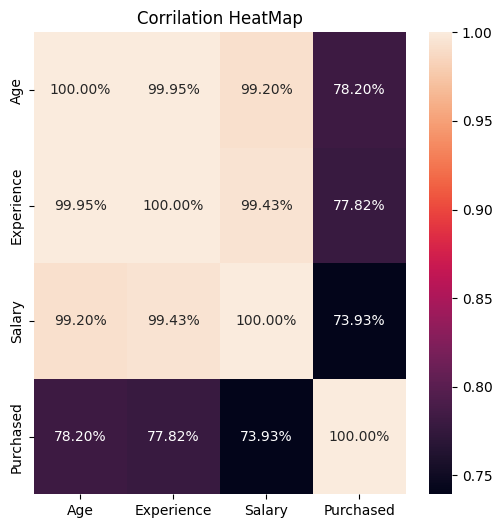

Upper Trangle:-
            Age  Experience    Salary  Purchased
Age         NaN     0.99951  0.991956   0.782000
Experience  NaN         NaN  0.994336   0.778207
Salary      NaN         NaN       NaN   0.739333
Purchased   NaN         NaN       NaN        NaN

Sorted Features:- 
['Experience', 'Salary']


In [8]:
import pandas as pd

df = pd.DataFrame({
    "Age":[22,25,28,30,35,40,45,50],
    "Experience":[1,3,6,8,13,18,23,28],
    "Salary":[25000,30000,40000,50000,70000,90000,120000,150000],
    "Purchased":[0,0,0,1,1,1,1,1]
})

corrilation_matrix = df.corr(numeric_only=True)
print("Corrilation Matrix:-")
print(corrilation_matrix)
print()
plt.figure(figsize=(6,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)

plt.title("Corrilation HeatMap")
plt.show()

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print("Upper Trangle:-")
print(upper_trangle)
print()

sorted_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.90)
]

print("Sorted Features:- ")
print(sorted_features)

In [14]:
import pandas as pd

df = pd.DataFrame({
    "Income":[25000,30000,40000,50000,70000,80000,100000,120000],
    "Age":[22,25,28,31,35,40,45,50],
    "Family_Size":[2,3,2,4,5,4,3,6],
    "Loan_Approved":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"]


classifire = RandomForestClassifier(random_state=42)

classifire.fit(x,y)

importance = classifire.feature_importances_


feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feture_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

      Features  Importance
1          Age    0.387045
0       Income    0.382588
2  Family_Size    0.230367


In [15]:
import pandas as pd

df = pd.DataFrame({
    "Study_Hours":[2,3,5,6,8,9,10,12],
    "Attendance":[60,65,70,75,80,90,95,98],
    "Sleep":[8,7,7,6,6,5,5,4],
    "Pass":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Pass"])
y = df["Pass"]

mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
    
)


final_mi_Score = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

final_mi_Score = final_mi_Score.sort_values(
    by = "MI Score",
    ascending=False
)

print("Final Mi Score is: ")
print(final_mi_Score)

Final Mi Score is: 
      Features  MI Score
0  Study_Hours  0.484524
1   Attendance  0.369940
2        Sleep  0.332440


In [18]:
import pandas as pd

df = pd.DataFrame({
    "Age":[20,22,25,28,30,35,40,45],
    "Income":[20000,25000,30000,40000,50000,70000,90000,120000],
    "City":[1,2,1,3,2,3,1,2],
    "Purchased":[0,0,0,1,1,1,1,1]
})


x = df.drop(columns=["Purchased"])
y = df["Purchased"]

model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=2
)

rfe.fit(x,y)

selected_columns = x.columns[rfe.get_support()]


ranking = pd.DataFrame({
    "Features":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Columns:")
print(selected_columns)

print("Ranking: ")
print(ranking)

Selected Columns:
Index(['Age', 'Income'], dtype='object')
Ranking: 
  Features  Rank
0      Age     1
1   Income     1
2     City     2


Corrilation Matrix:- 
               Area  Area_sqft     Price
Area       1.000000   0.999998  0.997388
Area_sqft  0.999998   1.000000  0.997457
Price      0.997388   0.997457  1.000000
Heatmap:-



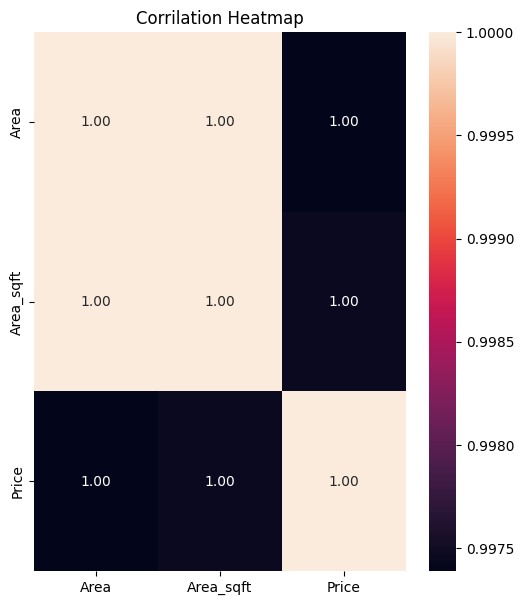

Upper Trangle:-

           Area  Area_sqft     Price
Area        NaN   0.999998  0.997388
Area_sqft   NaN        NaN  0.997457
Price       NaN        NaN       NaN
Selected Columns:-

['Area_sqft', 'Price']


In [21]:
import pandas as pd

df = pd.DataFrame({
    "Area":[1000,1200,1500,1800,2000,2300,2600,3000],
    "Area_sqft":[1002,1201,1501,1801,1998,2299,2601,3002],
    "Price":[20,25,35,45,55,65,80,95]
})

print("Corrilation Matrix:- ")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("Heatmap:-\n")
plt.figure(figsize=(6,7))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2f"
)
plt.title("Corrilation Heatmap")
plt.show()


print("Upper Trangle:-\n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)


print("Selected Columns:-\n")

selected_columns = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

print(selected_columns)

In [23]:
import pandas as pd

df = pd.DataFrame({
    "Area":[1000,1200,1500,1800,2000,2300,2600,3000],
    "Area_sqft":[1002,1201,1501,1801,1998,2299,2601,3002],
    "Price":[20,25,35,45,55,65,80,95]
})

x = df.drop(columns=["Price"])
y = df["Price"]

rf_classifire = RandomForestClassifier(random_state=42)

rf_classifire.fit(x,y)

importance = rf_classifire.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


    Features  Importance
0       Area    0.511492
1  Area_sqft    0.488508


In [24]:
import pandas as pd

df = pd.DataFrame({
    "Sugar":[80,85,90,110,120,140,160,180],
    "BP":[110,115,120,130,140,150,160,170],
    "BMI":[18,20,22,25,28,30,33,35],
    "Diabetes":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Diabetes"])
y = df["Diabetes"]

mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
        
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

  Features  MI Score
2      BMI  0.505357
0    Sugar  0.494940
1       BP  0.349107


In [26]:
import pandas as pd

df = pd.DataFrame({
    "Salary":[20000,25000,35000,45000,60000,80000,100000,120000],
    "Experience":[1,2,4,6,8,10,12,15],
    "Education":[1,2,2,3,3,4,4,5],
    "Promotion":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Promotion"])
y = df["Promotion"]

model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=2
)

rfe.fit(x,y)

selected_columns = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Features":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features:\n")
print(selected_columns)

print("Ranking:\n")
print(ranking)

Selected Features:

Index(['Salary', 'Education'], dtype='object')
Ranking:

     Features  Rank
0      Salary     1
1  Experience     2
2   Education     1


Corrilation Matrix:

           Height    Weight       BMI   Disease
Height   1.000000  1.000000  0.994135  0.872872
Weight   1.000000  1.000000  0.994135  0.872872
BMI      0.994135  0.994135  1.000000  0.851064
Disease  0.872872  0.872872  0.851064  1.000000
Heatmap:



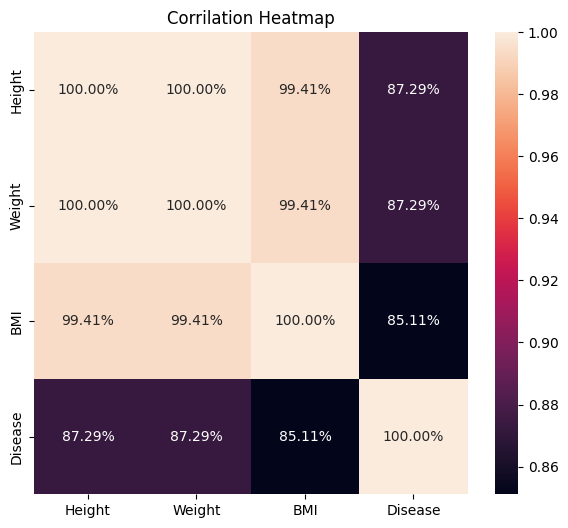

Upper Trangle:

         Height  Weight       BMI   Disease
Height      NaN     1.0  0.994135  0.872872
Weight      NaN     NaN  0.994135  0.872872
BMI         NaN     NaN       NaN  0.851064
Disease     NaN     NaN       NaN       NaN
Feature Recomandation:- 

['Weight', 'BMI']


In [28]:
import pandas as pd

df = pd.DataFrame({
    "Height":[150,155,160,165,170,175,180,185],
    "Weight":[45,50,55,60,65,70,75,80],
    "BMI":[20,21,21.5,22,22.5,23,23.5,24],
    "Disease":[0,0,0,0,1,1,1,1]
})

print("Corrilation Matrix:\n")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("Heatmap:\n")
plt.figure(figsize=(7,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()


print("Upper Trangle:\n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

print(upper_trangle)


print("Feature Recomandation:- \n")

drop_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

print(drop_features)


Corrilation Mathod:-
Corrilation Matrix:-

                Age    Income      City  Education  Purchased
Age        1.000000  0.992777  0.083041   0.837652   0.844151
Income     0.992777  1.000000  0.071868   0.808735   0.795205
City       0.083041  0.071868  1.000000   0.130744  -0.124035
Education  0.837652  0.808735  0.130744   1.000000   0.632456
Purchased  0.844151  0.795205 -0.124035   0.632456   1.000000
Heatmap



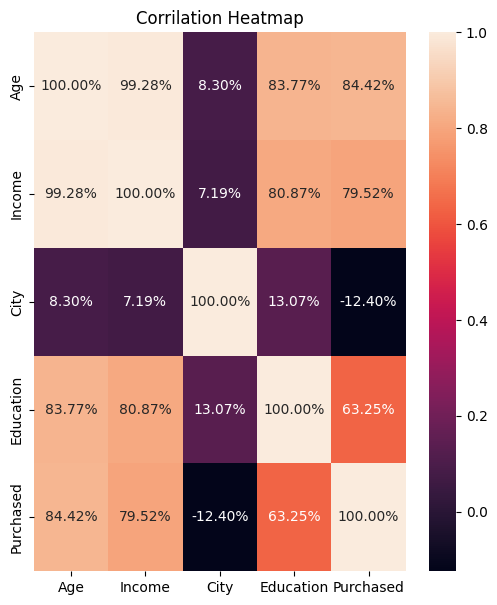

Upper Trangle:- 

           Age    Income      City  Education  Purchased
Age        NaN  0.992777  0.083041   0.837652   0.844151
Income     NaN       NaN  0.071868   0.808735   0.795205
City       NaN       NaN       NaN   0.130744  -0.124035
Education  NaN       NaN       NaN        NaN   0.632456
Purchased  NaN       NaN       NaN        NaN        NaN
Sorted Features:- 

['Income']
--------------------------------------------------

 Tree Features Importance:- 
Important Features:-
    Features  Importance
0        Age    0.468687
1     Income    0.437172
3  Education    0.062607
2       City    0.031534
--------------------------------------------------
Mutual Information: 

Mutual Imformation:- 
    Features  MI Score
0        Age  0.390774
1     Income  0.390774
3  Education  0.219940
2       City  0.000000
--------------------------------------------------
RFE
Selected Features:-

Index(['Age', 'City', 'Education'], dtype='object')
Ranking:- 

    Features  Rank
0        Age 

In [39]:
import pandas as pd

df = pd.DataFrame({
    "Age":[22,25,30,35,40,45,50,55],
    "Income":[25000,35000,50000,65000,80000,100000,120000,150000],
    "City":[1,2,3,1,2,3,1,2],
    "Education":[1,2,3,2,4,3,5,4],
    "Purchased":[0,0,0,1,1,1,1,1]
})
x = df.drop(columns=["Purchased"])
y = df["Purchased"]


print("\nCorrilation Mathod:-")

print("Corrilation Matrix:-\n")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)


print("Heatmap\n")
plt.figure(figsize=(6,7))
sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle:- \n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)


print("Sorted Features:- \n")

sorted_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.9)
]

print(sorted_features)

print("-"*50)

print("\n Tree Features Importance:- ")

rf_classifire = RandomForestClassifier(random_state=42)

rf_classifire.fit(x,y)

importance = rf_classifire.feature_importances_

features_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

features_importance = features_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Important Features:-")
print(features_importance)

print("-"*50)

print("Mutual Information: \n")
mi_score = mutual_info_classif(
    x,
    y,
    random_state=34
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print("Mutual Imformation:- ")
print(mi_df)


print("-"*50)

print("RFE")

model = LogisticRegression(max_iter=100)

rfe = RFE(
    estimator=model,
    n_features_to_select=3
)

rfe.fit(x,y)

selected_columns = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Features":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features:-\n")
print(selected_columns)

print("Ranking:- \n")
print(ranking)

Corrilation Matrix:- 

                Area  Area_meter  Bedrooms  Bathrooms     Price
Area        1.000000    0.999996  0.977890   0.976616  0.995295
Area_meter  0.999996    1.000000  0.977974   0.976307  0.995463
Bedrooms    0.977890    0.977974  1.000000   0.912871  0.971717
Bathrooms   0.976616    0.976307  0.912871   1.000000  0.969081
Price       0.995295    0.995463  0.971717   0.969081  1.000000
Heatmap:- 



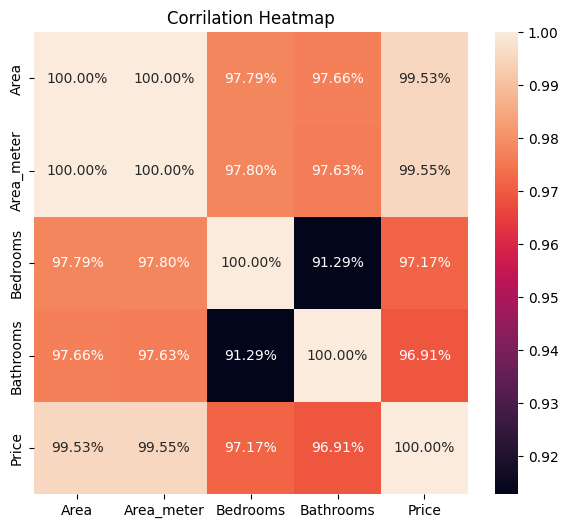

Upper Trangle:- 

            Area  Area_meter  Bedrooms  Bathrooms     Price
Area         NaN    0.999996  0.977890   0.976616  0.995295
Area_meter   NaN         NaN  0.977974   0.976307  0.995463
Bedrooms     NaN         NaN       NaN   0.912871  0.971717
Bathrooms    NaN         NaN       NaN        NaN  0.969081
Price        NaN         NaN       NaN        NaN       NaN
Selected Features:- 

['Area_meter', 'Bedrooms', 'Bathrooms', 'Price']


In [41]:
import pandas as pd

df = pd.DataFrame({
    "Area":[1000,1200,1500,1800,2100,2400,2700,3000],
    "Area_meter":[93,111,139,167,195,223,251,279],
    "Bedrooms":[2,2,3,3,4,4,5,5],
    "Bathrooms":[1,2,2,3,3,4,4,5],
    "Price":[30,36,45,55,68,80,95,110]
})

print("Corrilation Matrix:- \n")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)


print("Heatmap:- \n")

plt.figure(figsize=(7,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle:- \n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)


print("Selected Features:- \n")

selected_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

print(selected_features)

In [44]:
import pandas as pd

df = pd.DataFrame({
    "TV_Ads":[10,20,30,40,50,60,70,80],
    "Radio_Ads":[5,10,15,20,25,30,35,40],
    "Newspaper":[20,25,30,35,40,45,50,55],
    "Sales":[100,130,170,210,250,300,350,410]
})

x = df.drop(columns=["Sales"])
y = df["Sales"]

rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x,y)
importance = rf_classifier.feature_importances_

features_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

features_importance = features_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:-\n")
print(features_importance)

Feature Importance:-

    Features  Importance
1  Radio_Ads    0.346364
0     TV_Ads    0.342712
2  Newspaper    0.310924


In [45]:
import pandas as pd

df = pd.DataFrame({
    "Age":[22,25,28,30,35,40,45,50],
    "BMI":[18,20,22,24,26,28,30,32],
    "Exercise":[5,4,4,3,3,2,2,1],
    "Heart_Disease":[0,0,0,0,1,1,1,1]
})
x = df.drop(columns=["Heart_Disease"])
y = df["Heart_Disease"]


mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
    
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

   Features  MI Score
0       Age  0.425000
2  Exercise  0.386607
1       BMI  0.240774


In [46]:
import pandas as pd

df = pd.DataFrame({
    "Income":[20000,30000,40000,50000,60000,70000,80000,90000],
    "Age":[21,24,27,30,35,40,45,50],
    "Experience":[1,3,5,7,10,15,20,25],
    "Loan":[0,0,0,1,1,1,1,1]
})
x = df.drop(columns=["Loan"])
y = df["Loan"]

model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=2
)

rfe.fit(x,y)

selected_features = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Features":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features:- \n")
print(selected_features)

print("Features Ranking:- \n")
print(ranking)

Selected Features:- 

Index(['Income', 'Experience'], dtype='object')
Features Ranking:- 

     Features  Rank
0      Income     1
1         Age     2
2  Experience     1


Corrilation Method:- 


Corrilation Matrix:- 
            Engine_CC  HorsePower    Torque  Car_Price
Engine_CC    1.000000    0.996062  1.000000   0.981618
HorsePower   0.996062    1.000000  0.996062   0.994057
Torque       1.000000    0.996062  1.000000   0.981618
Car_Price    0.981618    0.994057  0.981618   1.000000
HeatMap:-



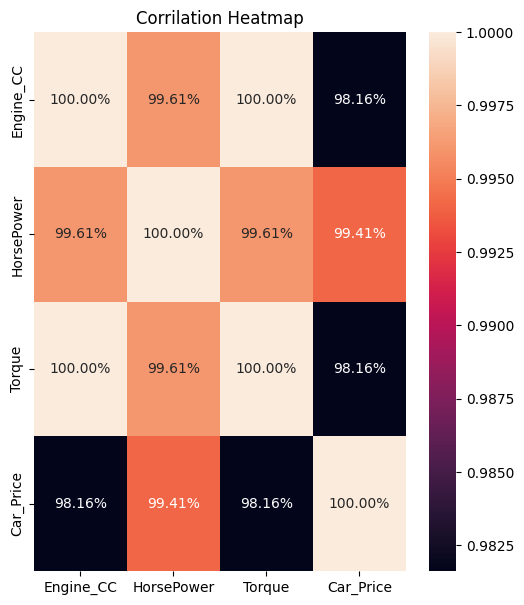

Upper Trangle
            Engine_CC  HorsePower    Torque  Car_Price
Engine_CC         NaN    0.996062  1.000000   0.981618
HorsePower        NaN         NaN  0.996062   0.994057
Torque            NaN         NaN       NaN   0.981618
Car_Price         NaN         NaN       NaN        NaN
Sorted Features
['HorsePower', 'Torque', 'Car_Price']
--------------------------------------------------
Tree Feature Importance
Feature Importance:- 
     Features  Importance
0   Engine_CC    0.358275
1  HorsePower    0.348279
2      Torque    0.293447


In [50]:
import pandas as pd

df = pd.DataFrame({
    "Engine_CC":[1000,1200,1400,1600,1800,2000,2200,2400],
    "HorsePower":[68,82,96,110,125,145,165,185],
    "Torque":[90,110,130,150,170,190,210,230],
    "Car_Price":[5,6,7,9,11,14,17,20]
})

x = df.drop(columns=["Car_Price"])
y = df["Car_Price"]

print("Corrilation Method:- \n")
print()
print("Corrilation Matrix:- ")

corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("HeatMap:-\n")
plt.figure(figsize=(6,7))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle")
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)

print("Sorted Features")

drop_one =[
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

print(drop_one)

print("-"*50)


print("Tree Feature Importance")

rf_regressor = RandomForestRegressor(random_state=42)
rf_regressor.fit(x,y)

importance = rf_regressor.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:- ")
print(feature_importance)

In [54]:
import pandas as pd

df = pd.DataFrame({
    "Attendance":[60,65,70,75,80,85,90,95],
    "Study_Hours":[2,3,4,5,6,7,8,9],
    "IQ":[90,95,98,102,105,110,115,120],
    "Result":[0,0,0,1,1,1,1,1]
})
x = df.drop(columns=["Result"])
y = df["Result"]



mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

print("-"*50)

print("RFE")

model = LogisticRegression(max_iter=100)

rfe = RFE(
    estimator=model,
    n_features_to_select=2
)

rfe.fit(x,y)

selected_columns = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Feature":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features:- ")
print(selected_columns)

print("Ranking:- ")
print(ranking)

      Features  MI Score
0   Attendance  0.411607
1  Study_Hours  0.332440
2           IQ  0.230357
--------------------------------------------------
RFE
Selected Features:- 
Index(['Attendance', 'IQ'], dtype='object')
Ranking:- 
       Feature  Rank
0   Attendance     1
1  Study_Hours     2
2           IQ     1


Corrilation Matrix:- 
            Weight       BMI  Body_Fat   Disease
Weight    1.000000  1.000000  0.995403  0.872872
BMI       1.000000  1.000000  0.995403  0.872872
Body_Fat  0.995403  0.995403  1.000000  0.878823
Disease   0.872872  0.872872  0.878823  1.000000
HeatMap:-


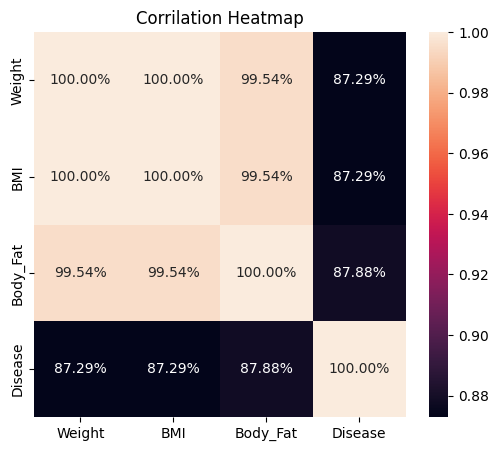

Upper Trangle:- 
          Weight  BMI  Body_Fat   Disease
Weight       NaN  1.0  0.995403  0.872872
BMI          NaN  NaN  0.995403  0.872872
Body_Fat     NaN  NaN       NaN  0.878823
Disease      NaN  NaN       NaN       NaN
Selected Features:- 
['BMI', 'Body_Fat']


In [56]:
import pandas as pd

df = pd.DataFrame({
    "Weight":[45,50,55,60,65,70,75,80],
    "BMI":[18.0,19.5,21.0,22.5,24.0,25.5,27.0,28.5],
    "Body_Fat":[12,14,16,18,21,24,27,30],
    "Disease":[0,0,0,0,1,1,1,1]
})

print("Corrilation Matrix:- ")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)
print("HeatMap:-")
plt.figure(figsize=(6,5))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()


print("Upper Trangle:- ")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)

print("Selected Features:- ")

drop_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.90)
]
print(drop_features)

In [57]:
import pandas as pd

df = pd.DataFrame({
    "Credit_Score":[550,580,620,650,700,750,800,850],
    "Income":[25000,30000,40000,50000,70000,90000,120000,150000],
    "Age":[22,25,28,32,36,40,45,50],
    "Approved":[0,0,0,1,1,1,1,1]
})
x = df.drop(columns=["Approved"])
y = df["Approved"]


rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x,y)

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

       Features  Importance
1        Income    0.363636
0  Credit_Score    0.353535
2           Age    0.282828


In [59]:
import pandas as pd

df = pd.DataFrame({
    "Rainfall":[200,250,300,350,400,450,500,550],
    "Temperature":[20,22,24,26,28,30,32,34],
    "Humidity":[55,60,65,70,75,80,85,90],
    "Crop_Yield":[30,35,42,50,60,70,82,95]
})
x = df.drop(columns=["Crop_Yield"])


mi_score =  mutual_info_regression(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

       Feature  MI Score
0     Rainfall  0.240774
1  Temperature  0.240774
2     Humidity  0.215774


Corrilation Method:- 
Corrilation Matrix:- 

                 Age    Income  Experience  Education      City  Purchased
Age         1.000000  0.992777    0.995655   0.975726  0.083041   0.844151
Income      0.992777  1.000000    0.999515   0.973009  0.071868   0.795205
Experience  0.995655  0.999515    1.000000   0.974108  0.071321   0.805011
Education   0.975726  0.973009    0.974108   1.000000  0.130744   0.843274
City        0.083041  0.071868    0.071321   0.130744  1.000000  -0.124035
Purchased   0.844151  0.795205    0.805011   0.843274 -0.124035   1.000000
Heatmap


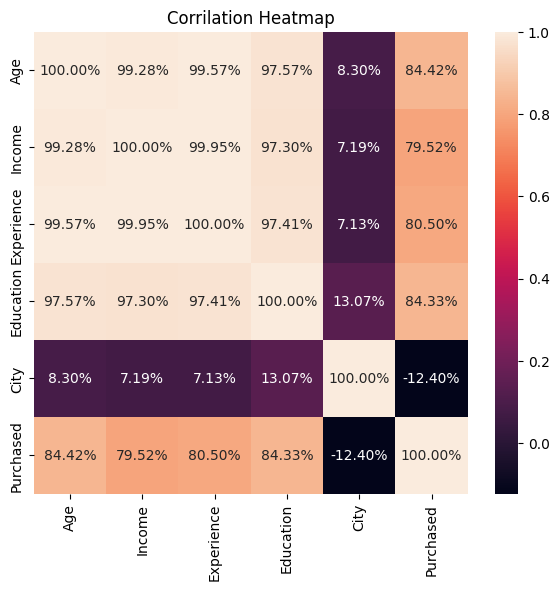

Upper Trangle
            Age    Income  Experience  Education      City  Purchased
Age         NaN  0.992777    0.995655   0.975726  0.083041   0.844151
Income      NaN       NaN    0.999515   0.973009  0.071868   0.795205
Experience  NaN       NaN         NaN   0.974108  0.071321   0.805011
Education   NaN       NaN         NaN        NaN  0.130744   0.843274
City        NaN       NaN         NaN        NaN       NaN  -0.124035
Purchased   NaN       NaN         NaN        NaN       NaN        NaN
Droped Features
['Income', 'Experience', 'Education']
Tree Feature Importance
    Features  Importance
1  Radio_Ads    0.346364
0     TV_Ads    0.342712
2  Newspaper    0.310924
Mutual Information Classifier
     Features  MI Score
2  Experience  0.526190
1      Income  0.463690
3   Education  0.338690
0         Age  0.317857
4        City  0.000000
RFE
Selected Features

Index(['Age', 'Income', 'Education'], dtype='object')
Ranking

     Features  Rank
0         Age     1
1      Income     

In [66]:
import pandas as pd

df = pd.DataFrame({
    "Age":[22,25,30,35,40,45,50,55],
    "Income":[25000,35000,50000,65000,80000,100000,120000,150000],
    "Experience":[1,3,6,9,12,16,20,25],
    "Education":[1,2,2,3,3,4,4,5],
    "City":[1,2,3,1,2,3,1,2],
    "Purchased":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Purchased"])
y = df["Purchased"]


print("Corrilation Method:- ")
print("Corrilation Matrix:- \n")

corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("Heatmap")
plt.figure(figsize=(7,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)

print("Droped Features")

drop_ones = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.90)
]
print(drop_ones)

print("="*50)

print("Tree Feature Importance")

rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x,y)

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(features_importance)

print("="*50)

print("Mutual Information Classifier")
mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)
print("="*50)

print("RFE")
model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=3
)

rfe.fit(x,y)

selected_features = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Features":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features\n")
print(selected_features)

print("Ranking\n")
print(ranking)

In [70]:
import pandas as pd

df = pd.DataFrame({
    "Temperature":[20,22,24,26,28,30,32,34],
    "Humidity":[40,45,50,55,60,65,70,75],
    "Rainfall":[100,120,140,160,180,200,220,240],
    "Crop_Yield":[30,35,42,50,60,70,82,95]
})
x = df.drop(columns=["Crop_Yield"])
y = df["Crop_Yield"]


mi_score = mutual_info_regression(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print("Mutual Information:- ")
print(mi_df)

Mutual Information:- 
       Feature  MI Score
2     Rainfall  0.697024
0  Temperature  0.655357
1     Humidity  0.655357


Corrilation Matrix

                 Age    Income  Experience  Education      City  Purchased
Age         1.000000  0.992777    0.995655   0.975726  0.083041   0.844151
Income      0.992777  1.000000    0.999515   0.973009  0.071868   0.795205
Experience  0.995655  0.999515    1.000000   0.974108  0.071321   0.805011
Education   0.975726  0.973009    0.974108   1.000000  0.130744   0.843274
City        0.083041  0.071868    0.071321   0.130744  1.000000  -0.124035
Purchased   0.844151  0.795205    0.805011   0.843274 -0.124035   1.000000
Corrilation Heatmap



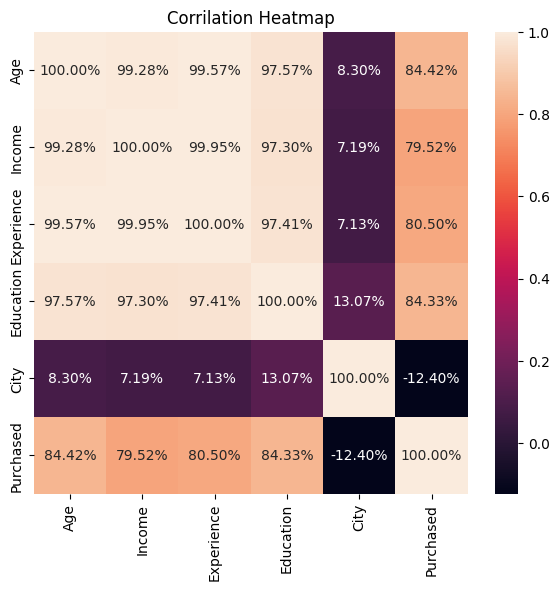

Upper Trangle

            Age    Income  Experience  Education      City  Purchased
Age         NaN  0.992777    0.995655   0.975726  0.083041   0.844151
Income      NaN       NaN    0.999515   0.973009  0.071868   0.795205
Experience  NaN       NaN         NaN   0.974108  0.071321   0.805011
Education   NaN       NaN         NaN        NaN  0.130744   0.843274
City        NaN       NaN         NaN        NaN       NaN  -0.124035
Purchased   NaN       NaN         NaN        NaN       NaN        NaN
Droped Features

['Income', 'Experience', 'Education']


In [71]:
df = pd.DataFrame({
    "Weight":[45,50,55,60,65,70,75,80],
    "Height":[150,155,160,165,170,175,180,185],
    "BMI":[20,21,21.5,22,22.5,23,23.5,24],
    "Disease":[0,0,0,0,1,1,1,1]
})

print("Corrilation Matrix\n")
corilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("Corrilation Heatmap\n")
plt.figure(figsize=(7,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()


print("Upper Trangle\n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)


print("Droped Features\n")

drop_once = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.90)
]

print(drop_once)

In [72]:
df = pd.DataFrame({
    "TV":[10,20,30,40,50,60,70,80],
    "Radio":[5,8,12,15,20,25,28,30],
    "Newspaper":[30,35,40,45,50,55,60,65],
    "Sales":[100,140,180,220,260,320,380,430]
})
x = df.drop(columns=["Sales"])
y = df["Sales"]


rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x,y)

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

     Feature  Importance
1      Radio    0.346364
0         TV    0.342712
2  Newspaper    0.310924


In [73]:
df = pd.DataFrame({
    "Study":[2,3,4,5,6,7,8,9],
    "Sleep":[8,8,7,7,6,6,5,5],
    "Attendance":[60,65,70,75,80,85,90,95],
    "Pass":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Pass"])
y = df["Pass"]

model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=2
    
)

rfe.fit(x,y)

selected_columns = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Feature":x.columns,
    "Rank":rfe.ranking_
})

print("Selected Features:- \n")
print(selected_columns)

print("Feature Ranking:- \n")
print(ranking)

Selected Features:- 

Index(['Study', 'Attendance'], dtype='object')
Feature Ranking:- 

      Feature  Rank
0       Study     1
1       Sleep     2
2  Attendance     1


In [74]:
df = pd.DataFrame({
    "Income":[20,30,40,50,60,70,80,90],
    "Savings":[2,5,7,9,12,15,20,25],
    "Loan":[0,0,0,1,1,1,1,1]
})
x = df.drop(columns=["Loan"])
y = df["Loan"]


rf_classifier = RandomForestClassifier(random_state=41)

rf_classifier.fit(x,y)

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

   Feature  Importance
0   Income         0.5
1  Savings         0.5


Corrilation Matrix
            Age  Experience  Salary
Age         1.0         1.0     1.0
Experience  1.0         1.0     1.0
Salary      1.0         1.0     1.0
Heatmap



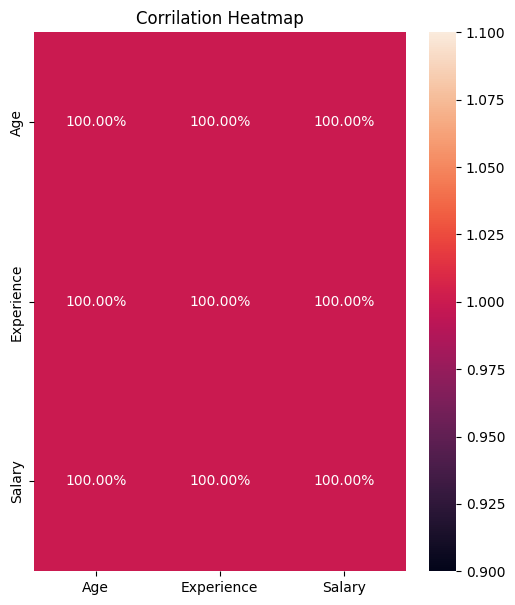

Upper Trangle:- 

            Age  Experience  Salary
Age         NaN         1.0     1.0
Experience  NaN         NaN     1.0
Salary      NaN         NaN     NaN
Sorted Features

['Experience', 'Salary']


In [77]:
df = pd.DataFrame({
    "Age":[22,24,26,28,30,32,34,36],
    "Experience":[1,3,5,7,9,11,13,15],
    "Salary":[3,4,5,6,7,8,9,10]
})


print("Corrilation Matrix")
corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)


print("Heatmap\n")
plt.figure(figsize=(6,7))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2%"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle:- \n")

upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)

print("Sorted Features\n")

sorted_features = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.9)
]

print(sorted_features)

In [78]:
df = pd.DataFrame({
    "Pulse":[70,72,75,80,85,90,95,100],
    "BP":[110,115,120,130,140,150,160,170],
    "Heart_Disease":[0,0,0,0,1,1,1,1]
})

x = df.drop(columns=["Heart_Disease"])
y = df["Heart_Disease"]


mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

  Feature  MI Score
1      BP  0.369940
0   Pulse  0.303274


In [80]:
df = pd.DataFrame({
    "Engine":[1000,1200,1400,1600,1800,2000,2200,2400],
    "Torque":[90,110,130,150,170,190,210,230],
    "Price":[5,6,8,10,12,15,18,21]
})

x = df.drop(columns=["Price"])
y = df["Price"]

rf_rigressor = RandomForestRegressor(random_state=42)

rf_rigressor.fit(x,y)

importance = rf_rigressor.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

  Features  Importance
0   Engine    0.505912
1   Torque    0.494088


Corrilation

Corrilation Matrix:-
                 Age  Experience    Income  Education      City    Family  \
Age         1.000000    0.995655  0.992777   0.975726  0.083041  0.975726   
Experience  0.995655    1.000000  0.999515   0.974108  0.071321  0.974108   
Income      0.992777    0.999515  1.000000   0.973009  0.071868  0.973009   
Education   0.975726    0.974108  0.973009   1.000000  0.130744  1.000000   
City        0.083041    0.071321  0.071868   0.130744  1.000000  0.130744   
Family      0.975726    0.974108  0.973009   1.000000  0.130744  1.000000   
Purchased   0.844151    0.805011  0.795205   0.843274 -0.124035  0.843274   

            Purchased  
Age          0.844151  
Experience   0.805011  
Income       0.795205  
Education    0.843274  
City        -0.124035  
Family       0.843274  
Purchased    1.000000  
Heatmap



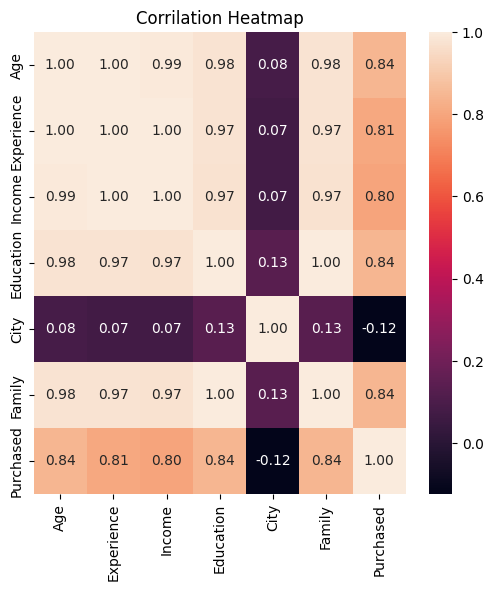

Upper Trangle:- 

            Age  Experience    Income  Education      City    Family  \
Age         NaN    0.995655  0.992777   0.975726  0.083041  0.975726   
Experience  NaN         NaN  0.999515   0.974108  0.071321  0.974108   
Income      NaN         NaN       NaN   0.973009  0.071868  0.973009   
Education   NaN         NaN       NaN        NaN  0.130744  1.000000   
City        NaN         NaN       NaN        NaN       NaN  0.130744   
Family      NaN         NaN       NaN        NaN       NaN       NaN   
Purchased   NaN         NaN       NaN        NaN       NaN       NaN   

            Purchased  
Age          0.844151  
Experience   0.805011  
Income       0.795205  
Education    0.843274  
City        -0.124035  
Family       0.843274  
Purchased         NaN  
Droped Features:-

['Experience', 'Income', 'Education', 'Family']
     Features  Importance
3   Education    0.232323
0         Age    0.222222
5      Family    0.202020
1  Experience    0.181818
2      Income   

In [86]:
df = pd.DataFrame({
    "Age":[22,25,30,35,40,45,50,55],
    "Experience":[1,3,6,9,12,16,20,25],
    "Income":[25000,35000,50000,65000,80000,100000,120000,150000],
    "Education":[1,2,2,3,3,4,4,5],
    "City":[1,2,3,1,2,3,1,2],
    "Family":[2,3,3,4,4,5,5,6],
    "Purchased":[0,0,0,1,1,1,1,1]
})

x = df.drop(columns=["Purchased"])
y = df["Purchased"]


print("Corrilation\n")
print("Corrilation Matrix:-")

corrilation_matrix = df.corr(numeric_only=True)
print(corrilation_matrix)

print("Heatmap\n")
plt.figure(figsize=(6,6))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    fmt=".2f"
)
plt.title("Corrilation Heatmap")
plt.show()

print("Upper Trangle:- \n")
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)
print(upper_trangle)


print("Droped Features:-\n")
drop_one = [
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.90)
]
print(drop_one)


print("="*50)


rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x,y)

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Features":x.columns,
    "Importance":importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
print(feature_importance)

print("="*50)


mi_score = mutual_info_classif(
    x,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Features":x.columns,
    "MI Score":mi_score
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)


print("="*50)


model = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=model,
    n_features_to_select=3
)

rfe.fit(x,y)

selected_features = x.columns[rfe.get_support()]

ranking = pd.DataFrame({
    "Feature":x.columns,
    "Rank":rfe.ranking_
})

ranking = ranking.sort_values(
    by="Rank",
    ascending=True
)


print("Selected Features:- \n")
print(selected_features)

print("Ranking\n")
print(ranking)